# Лабораторная работа 5: тематическое моделирование и кластеризация

**Задача 1 (практика 3).** Разработать систему тематического моделирования для
автоматического анализа и категоризации собранных веб-данных: предобработка
и векторизация, методы LDA и NMF, оценка качества и интерпретация, визуализация
тематических распределений. Минимум два датасета из практики 2 — новостные статьи
(200+ документов) и описания товаров (200+).

**Задача 2 (пример 2).** Собрать блюда городов из веба, закодировать города векторами
частотности блюд и кластеризовать, проверив результат содержательно.

**Результат.** Оба требования по объёму выполнены: собрано 240 новостей и 245 товаров
с описаниями. NMF оказался заметно сильнее LDA на новостях — **coherence c_v 0.54
против 0.35**; на товарах NMF дал **0.80**, разложив каталог на семейства моделей.
Кластеризация городов устойчива: три метода дали **одинаковое разбиение, индекс Rand 1.00**,
и оно совпадает с реальными кулинарными традициями.

| Требование задания | Что получилось |
|---|---|
| Новостные статьи, 200+ документов | 240 документов, медиана 55 слов |
| Описания товаров, 200+ | 245 записей, описание у всех, в работе 212 |
| Методы LDA и NMF | gensim `LdaModel` и sklearn `NMF` по TF-IDF |
| Подбор числа тем | авто по coherence c_v в диапазоне 3..20 |
| 1. Визуализации тем | топ-слова столбиками, сравнение методов |
| 2. Тематические распределения по документам | тепловая карта + CSV с долями тем |
| 3. Ключевые слова с весами | JSON-выгрузка по каждой теме |
| 4. Coherence score | график зависимости от K, выбор максимума |
| 5. Word clouds (опционально) | есть |
| Кластеризация городов | k-means, иерархическая, спектральная + PCA, локоть, silhouette |

Ниже — прогон целиком: предобработка, подбор K, темы обоих корпусов, кластеризация.

In [1]:
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import Image, display

LAB = Path.cwd()
if not (LAB / "topic_modeling.py").exists() and (LAB / "lab5" / "topic_modeling.py").exists():
    LAB = LAB / "lab5"
sys.path.insert(0, str(LAB))

OUTPUT = LAB / "output"
DATA = LAB.parent / "lab4" / "output"

def run(*command, tail=None):
    print("$", " ".join(str(part) for part in command))
    result = subprocess.run([sys.executable, *[str(part) for part in command]],
                            cwd=LAB, capture_output=True, text=True,
                            encoding="utf-8", errors="replace")
    lines = (result.stdout + result.stderr).splitlines()
    shown = lines[-tail:] if tail else lines
    print("\n".join(shown))

    problems = [line for line in lines
                if ("Error" in line or "Traceback" in line) and line not in shown]
    if problems:
        print("\nОшибки из полного вывода:")
        print("\n".join(problems[:10]))
    return result.returncode

def show(name, width=1000):
    path = OUTPUT / name
    if path.exists():
        display(Image(filename=str(path), width=width))
    else:
        print("нет файла", path.name)

print("Рабочая папка:", LAB)
print("Данные практики 2:", DATA, "—", "найдены" if DATA.exists() else "НЕ НАЙДЕНЫ")
for package in ("gensim", "sklearn", "pymorphy3", "wordcloud"):
    module = __import__(package)
    print(f"{package:12} {getattr(module, '__version__', 'ok')}")

Рабочая папка: /tmp/claude-0/-home-claude/37419b0e-7b34-5281-aca7-ee316eaa2693/scratchpad/project/lab5
Данные практики 2: /tmp/claude-0/-home-claude/37419b0e-7b34-5281-aca7-ee316eaa2693/scratchpad/project/lab4/output — найдены


gensim       4.4.0


sklearn      1.9.1
pymorphy3    2.0.6
wordcloud    1.9.6


---
## Тесты

Сеть не нужна: модели проверяются на маленьком корпусе, кластеризация — на городах
с заранее известной кухней.

In [2]:
run("-m", "pytest", "test_lab5.py", "-q", tail=8)

$ -m pytest test_lab5.py -q


=============================== warnings summary ===============================
test_lab5.py::test_three_methods_find_the_same_culinary_groups
test_lab5.py::test_top_dishes_describe_the_cluster
  /usr/local/lib/python3.13/dist-packages/sklearn/manifold/_spectral_embedding.py:325: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
    warnings.warn(

-- Docs: https://docs.pytest.org/en/stable/how-to/capture-warnings.html
21 passed, 2 warnings in 1.98s


0

---
# Задание 1: тематическое моделирование

## Предобработка

Документ новости — заголовок и краткое описание, документ товара — название и описание
с карточки. Слова приводятся к леммам, стоп-слова и слова короче трёх букв выбрасываются.

In [3]:
import preprocess

for name in ("news", "products", "mixed"):
    documents, stats = preprocess.prepare(name, DATA)
    lengths = sorted(len(document["tokens"]) for document in documents)
    middle = lengths[len(lengths) // 2] if lengths else 0
    print(f"{name:9} загружено {stats['loaded']:4}, отброшено коротких {stats['dropped']:3}, "
          f"в работе {stats['kept']:4}, медиана длины {middle:3} слов")

news      загружено  240, отброшено коротких   0, в работе  240, медиана длины  55 слов
products  загружено  245, отброшено коротких  33, в работе  212, медиана длины  14 слов
mixed     загружено  485, отброшено коротких  33, в работе  452, медиана длины  46 слов


In [4]:
documents, _ = preprocess.prepare("news", DATA)
print("Пример документа:")
print(" ", documents[0]["title"][:80])
print(" леммы:", " ".join(documents[0]["tokens"][:20]))

Пример документа:
  Борьба с ИИ-спагетти: C4 + Structurizr
 леммы: борьба спагетти structurizr писать код быстро превращать архитектура лапша неделя инженерный лаборатория микрофабрика попробовать решить model structurizr dsl получить рабочий


## Подбор числа тем по coherence

Перебираем K от 3 до 20, для каждого считаем c_v и берём максимум.

In [5]:
run("topic_modeling.py", "--dataset", "news", "--method", "both",
    "--topics", "auto", "--compare", "--output", "news_auto", tail=14)

$ topic_modeling.py --dataset news --method both --topics auto --compare --output news_auto


  сравнение: выше coherence у NMF (0.5405)
Результаты: /tmp/claude-0/-home-claude/37419b0e-7b34-5281-aca7-ee316eaa2693/scratchpad/project/lab5/output
  news_auto_coherence_lda.png
  news_auto_coherence_nmf.png
  news_auto_compare.png
  news_auto_documents_lda.csv
  news_auto_documents_lda.png
  news_auto_documents_nmf.csv
  news_auto_documents_nmf.png
  news_auto_topics.json
  news_auto_topwords_lda.png
  news_auto_topwords_nmf.png
  news_auto_wordcloud_lda.png
  news_auto_wordcloud_nmf.png


0

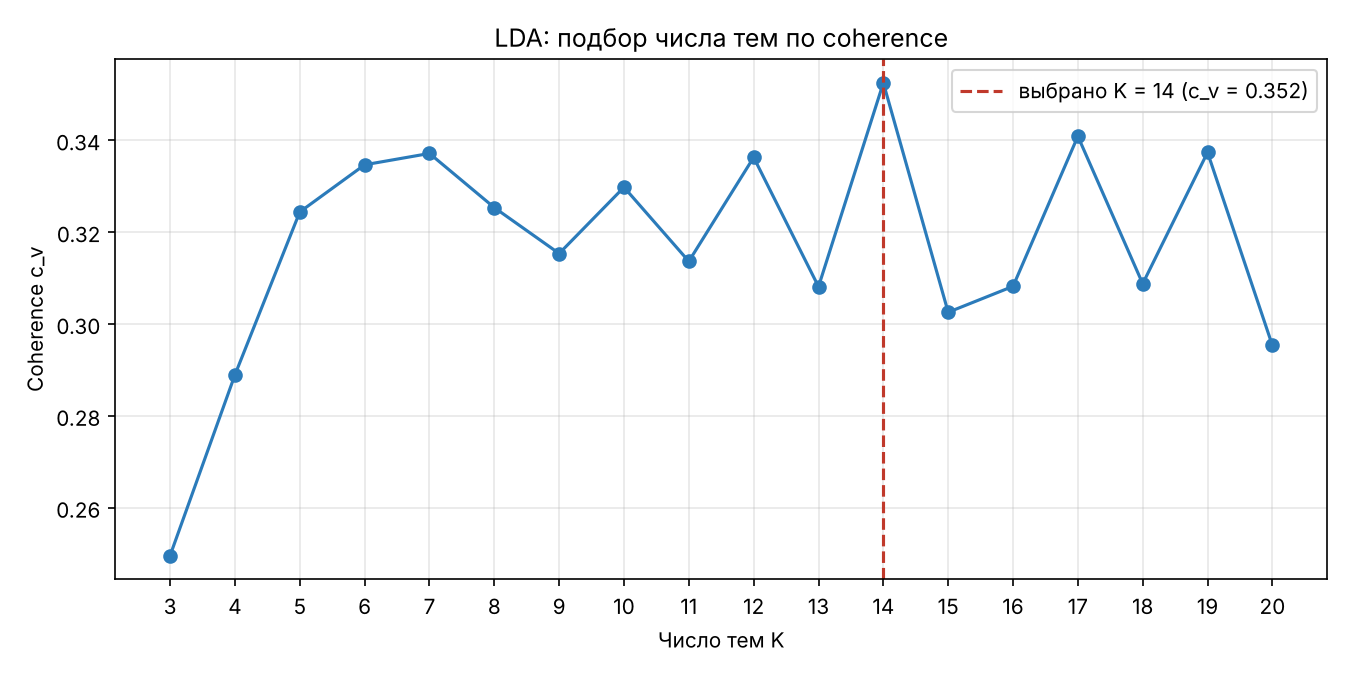

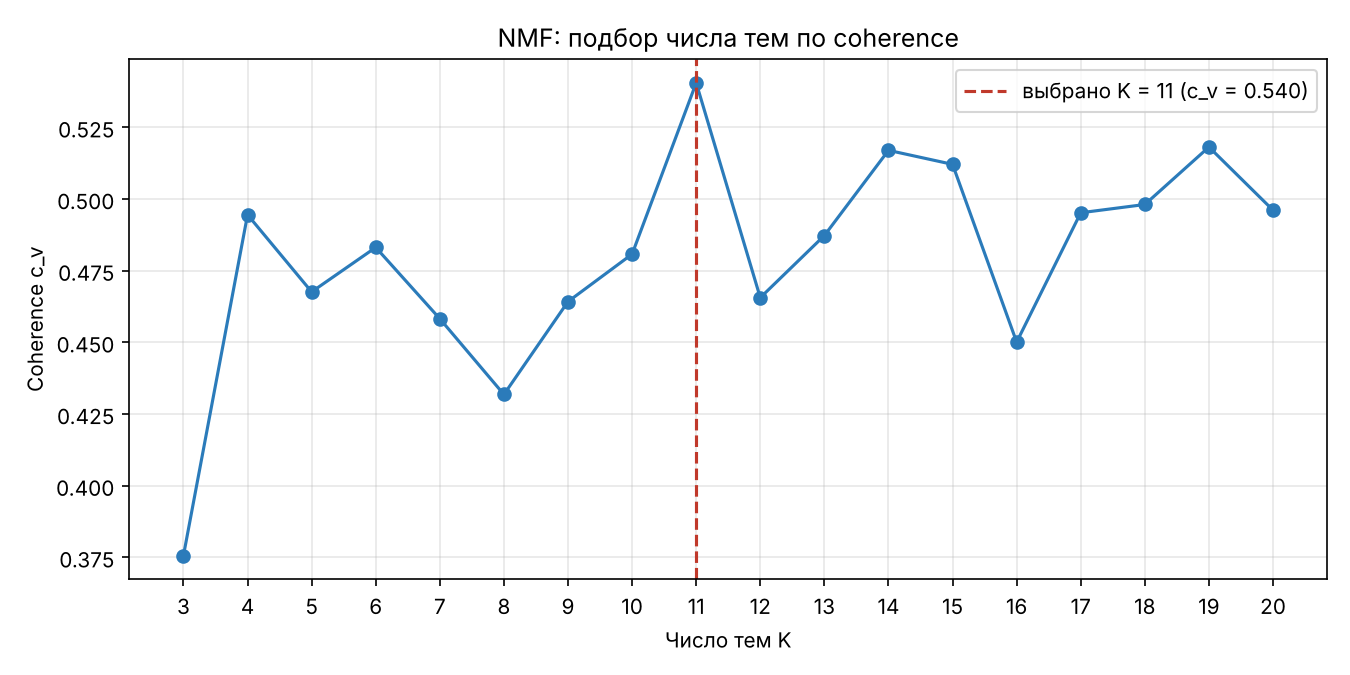

In [6]:
show("news_auto_coherence_lda.png")
show("news_auto_coherence_nmf.png")

Темы, найденные каждым методом:

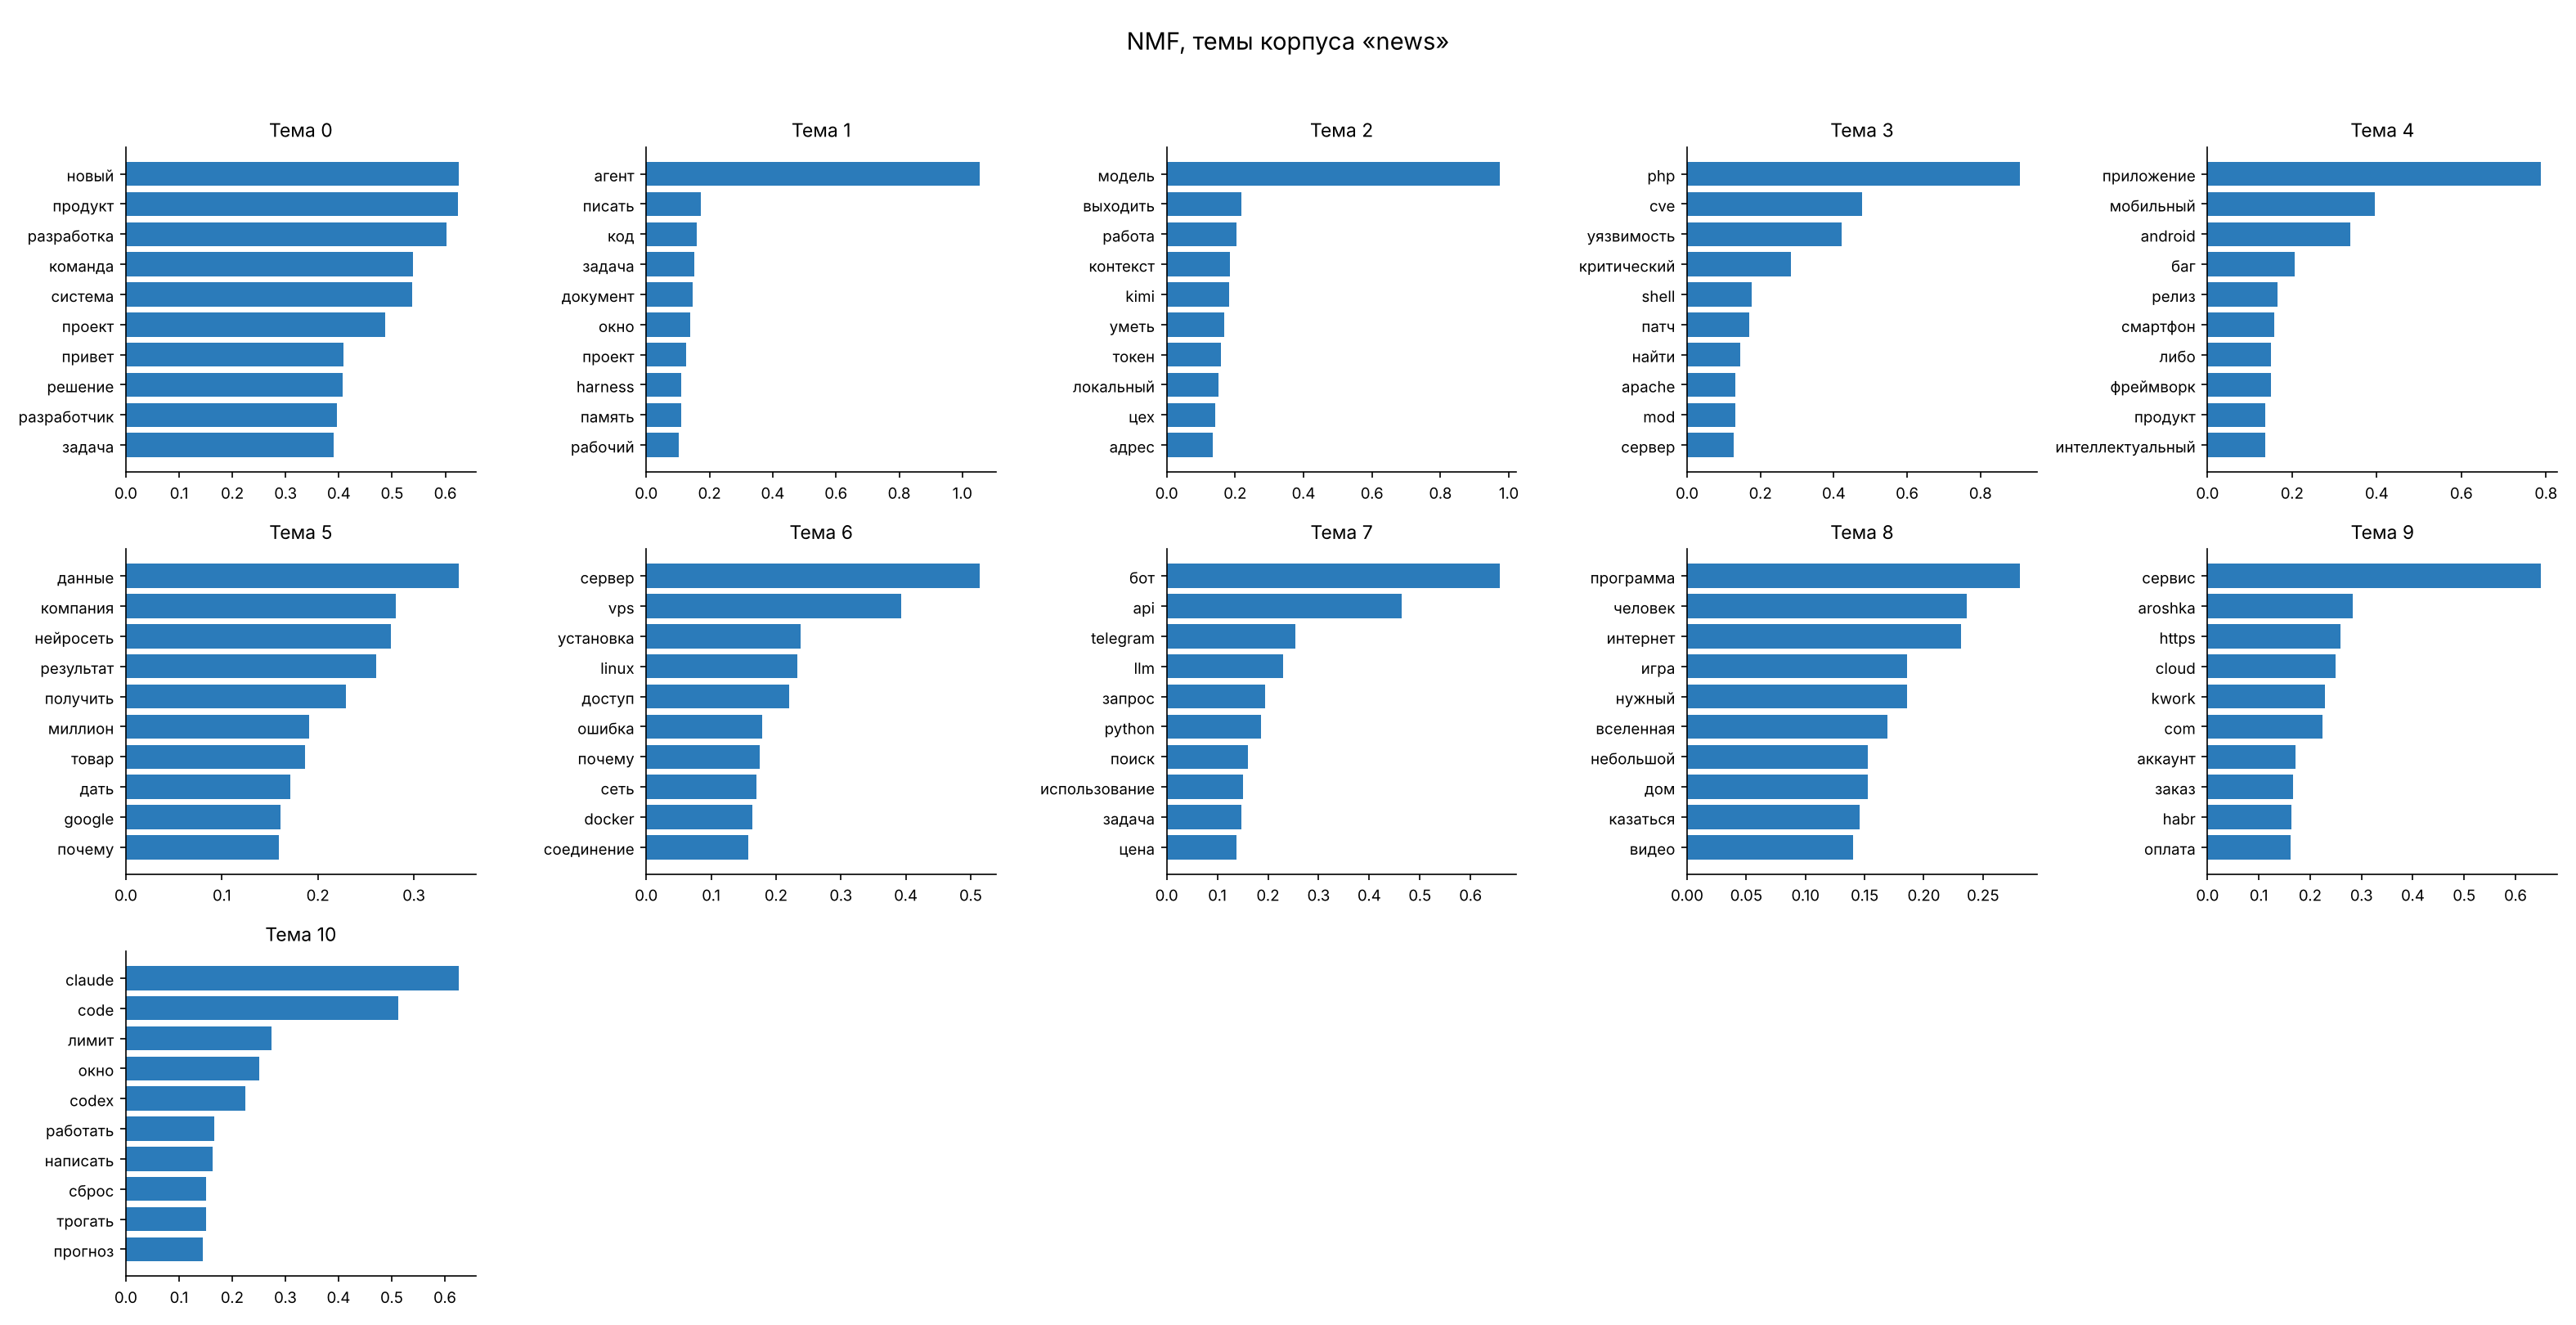

In [7]:
show("news_auto_topwords_nmf.png", width=1400)

## Ключевые слова с весами

Из JSON-выгрузки — то, что требуется третьим пунктом задания.

In [8]:
import json

result = json.loads((OUTPUT / "news_auto_topics.json").read_text(encoding="utf-8"))
for block in result["results"]:
    print(f"{block['method'].upper()}: тем {block['topics']}, coherence {block['coherence']:.4f}")
print()

nmf = next(block for block in result["results"] if block["method"] == "nmf")
for topic in nmf["keywords"][:6]:
    words = ", ".join(f"{item['word']} ({item['weight']:.3f})" for item in topic["words"][:6])
    print(f"  тема {topic['topic']}: {words}")

LDA: тем 14, coherence 0.3525
NMF: тем 11, coherence 0.5405

  тема 0: новый (0.626), продукт (0.623), разработка (0.602), команда (0.539), система (0.538), проект (0.487)
  тема 1: агент (1.054), писать (0.173), код (0.160), задача (0.152), документ (0.148), окно (0.139)
  тема 2: модель (0.974), выходить (0.218), работа (0.204), контекст (0.184), kimi (0.182), уметь (0.168)
  тема 3: php (0.909), cve (0.478), уязвимость (0.422), критический (0.283), shell (0.176), патч (0.170)
  тема 4: приложение (0.788), мобильный (0.396), android (0.337), баг (0.205), релиз (0.165), смартфон (0.158)
  тема 5: данные (0.347), компания (0.281), нейросеть (0.276), результат (0.261), получить (0.230), миллион (0.191)


## Распределение тем по документам

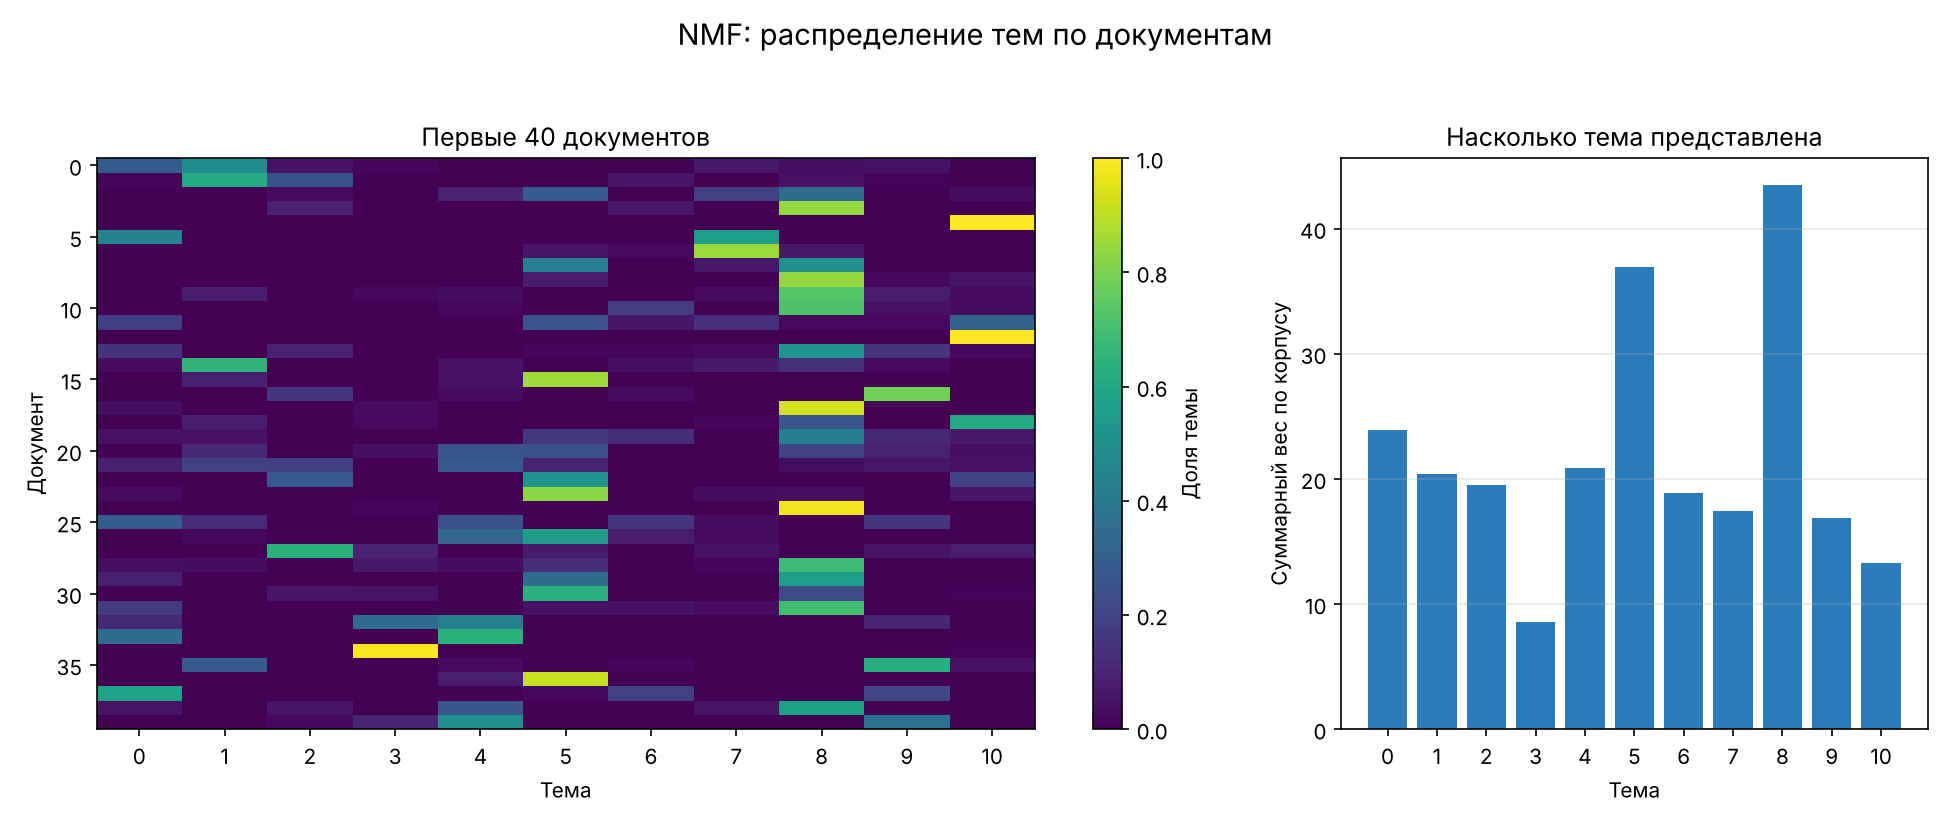

In [9]:
show("news_auto_documents_nmf.png", width=1200)

In [10]:
import csv

with (OUTPUT / "news_auto_documents_nmf.csv").open(encoding="utf-8-sig") as handle:
    rows = list(csv.DictReader(handle))

print("документов в выгрузке:", len(rows))
print()
for row in rows[:8]:
    print(f"  тема {row['главная тема']:>2} ({row['доля главной темы']})  {row['title'][:62]}")

документов в выгрузке: 240

  тема  1 (0.4876)  Борьба с ИИ-спагетти: C4 + Structurizr
  тема  1 (0.613)  Harness engineering: где на самом деле ломается агентная разра
  тема  8 (0.3616)  От отдела к компании: как объединить ИИ-навыки
  тема  8 (0.8425)  Я не умею программировать и рисовать, но сделал гео-игру про с
  тема 10 (1.0)  Как я сделал виджет лимитов Claude, а в нем поселился краб
  тема  7 (0.5585)  Системный анализ в эпоху LLM
  тема  7 (0.8509)  RAG-бот по материалам эксперта: как я мерил качество поиска и 
  тема  8 (0.5009)  «Счастье для всех, даром, и пусть никто не уйдёт обиженный»


## Облака слов

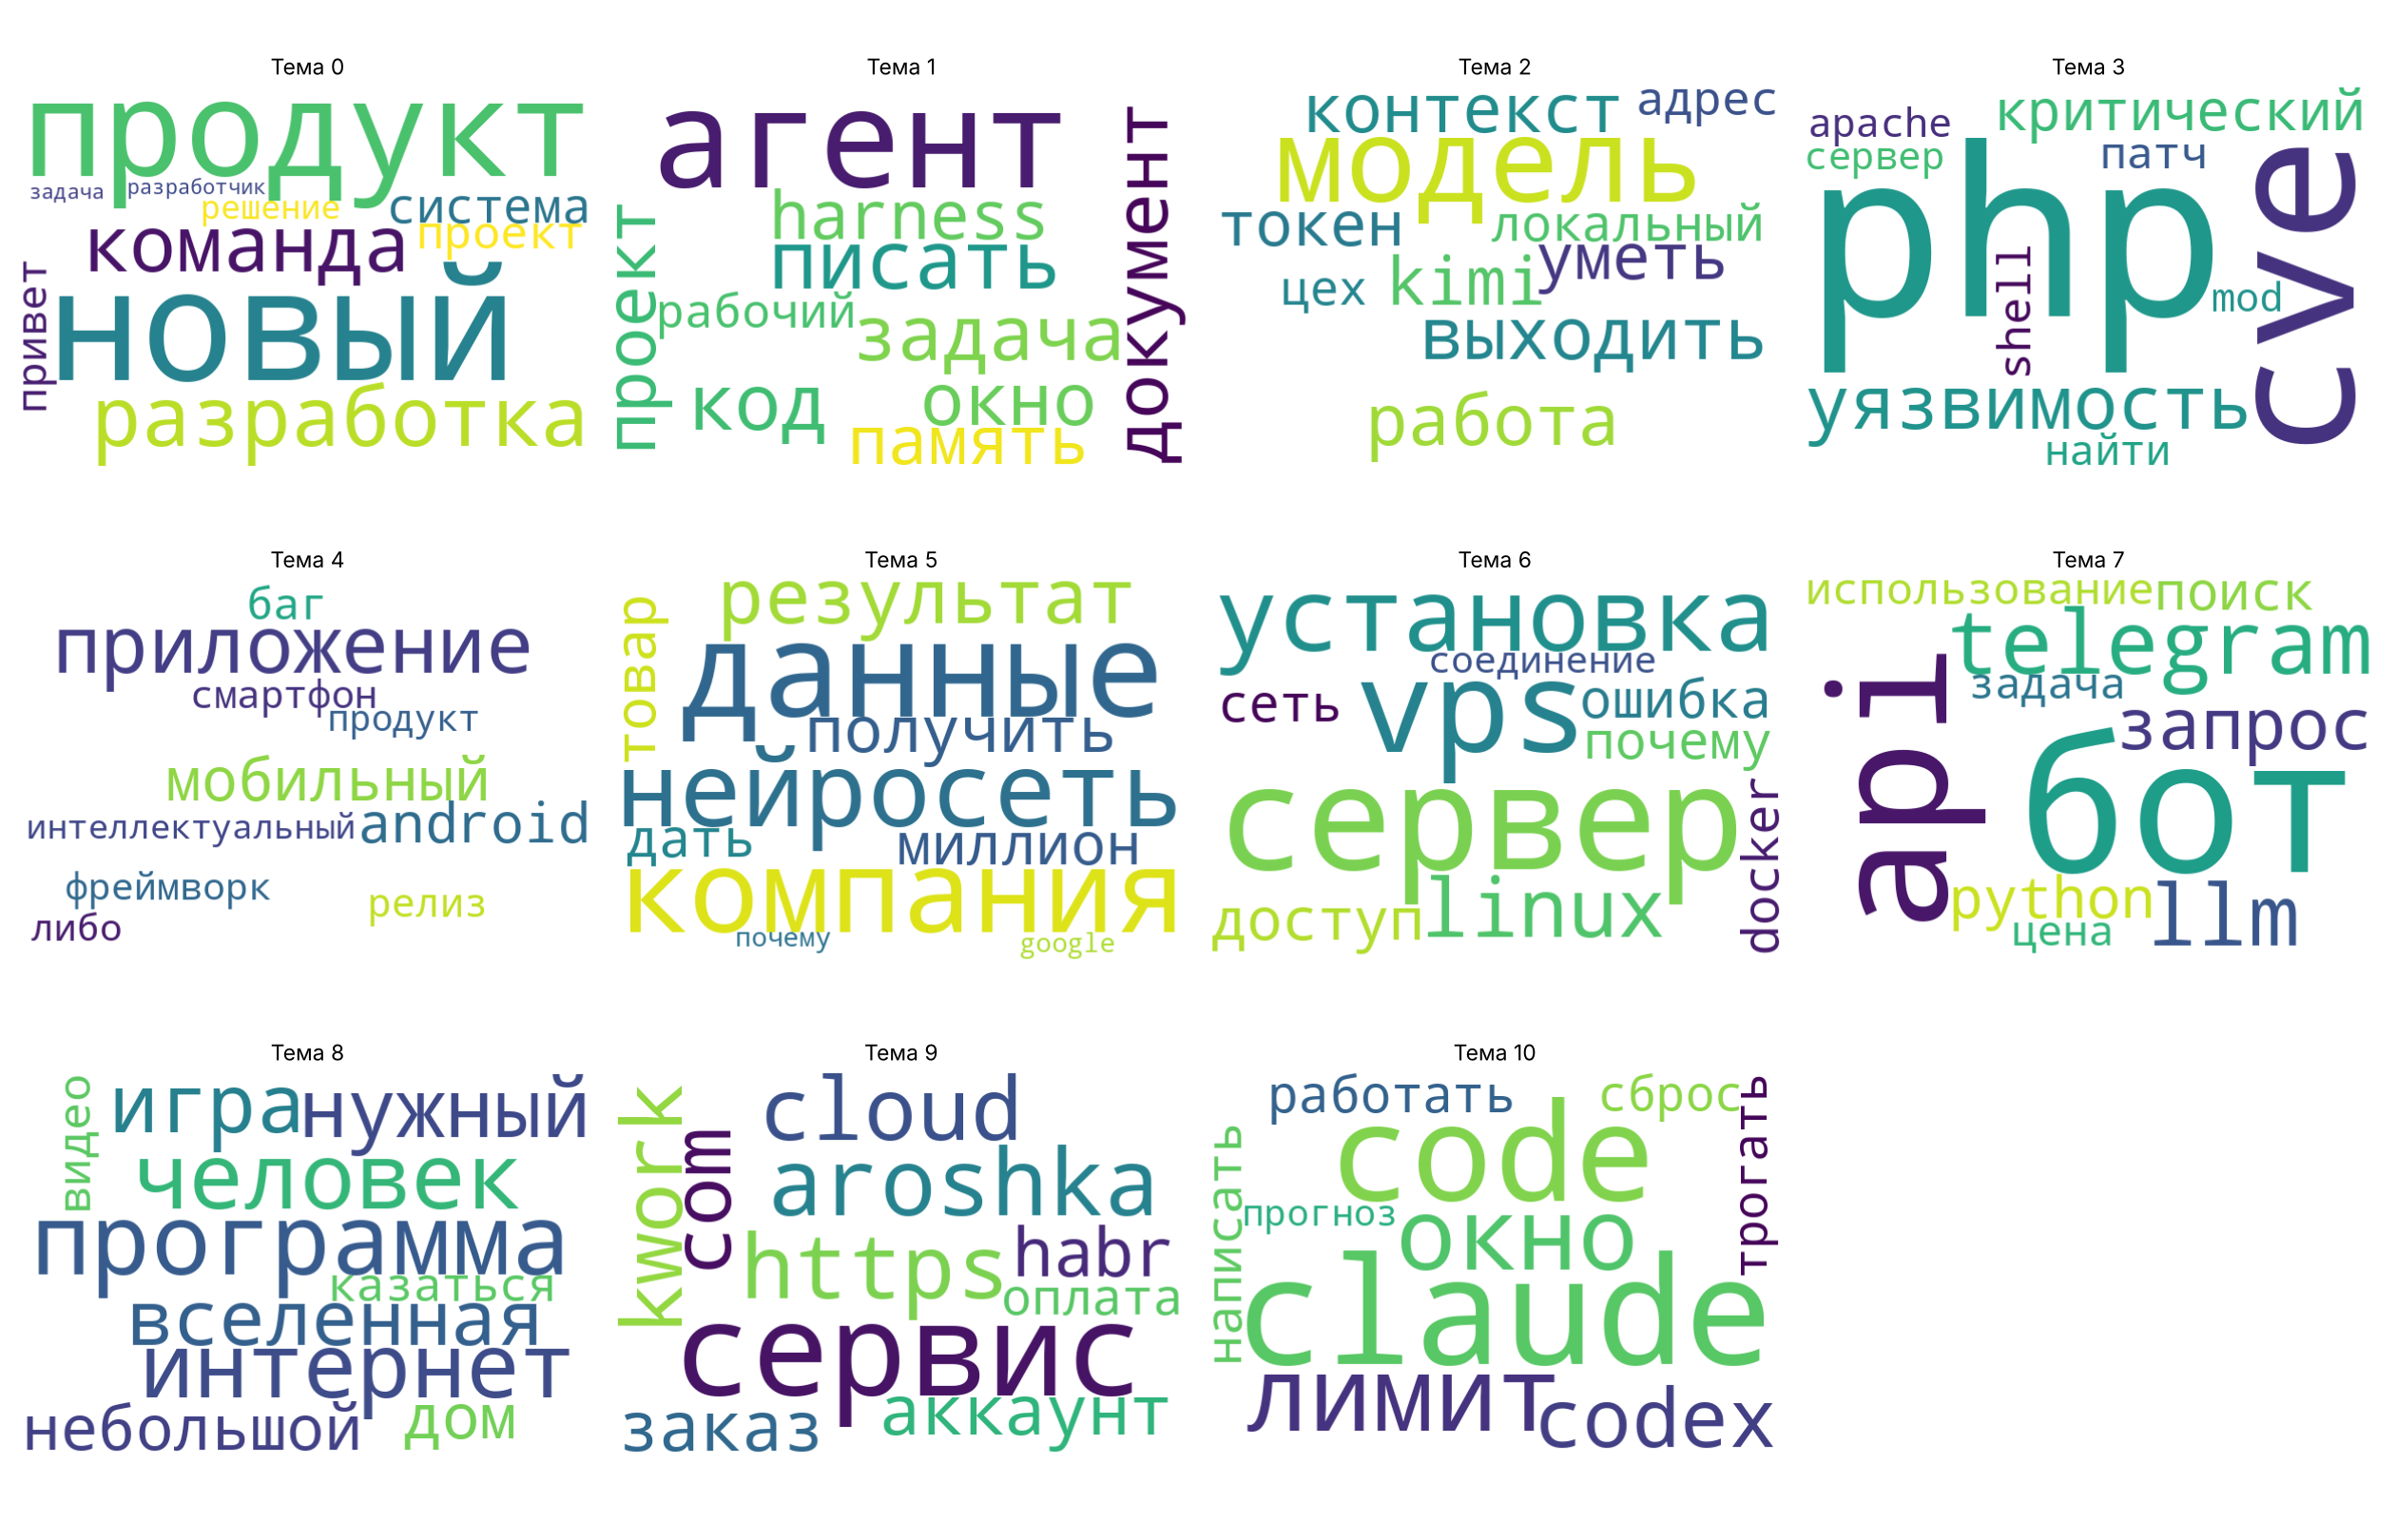

In [11]:
show("news_auto_wordcloud_nmf.png", width=1300)

## Сравнение LDA и NMF

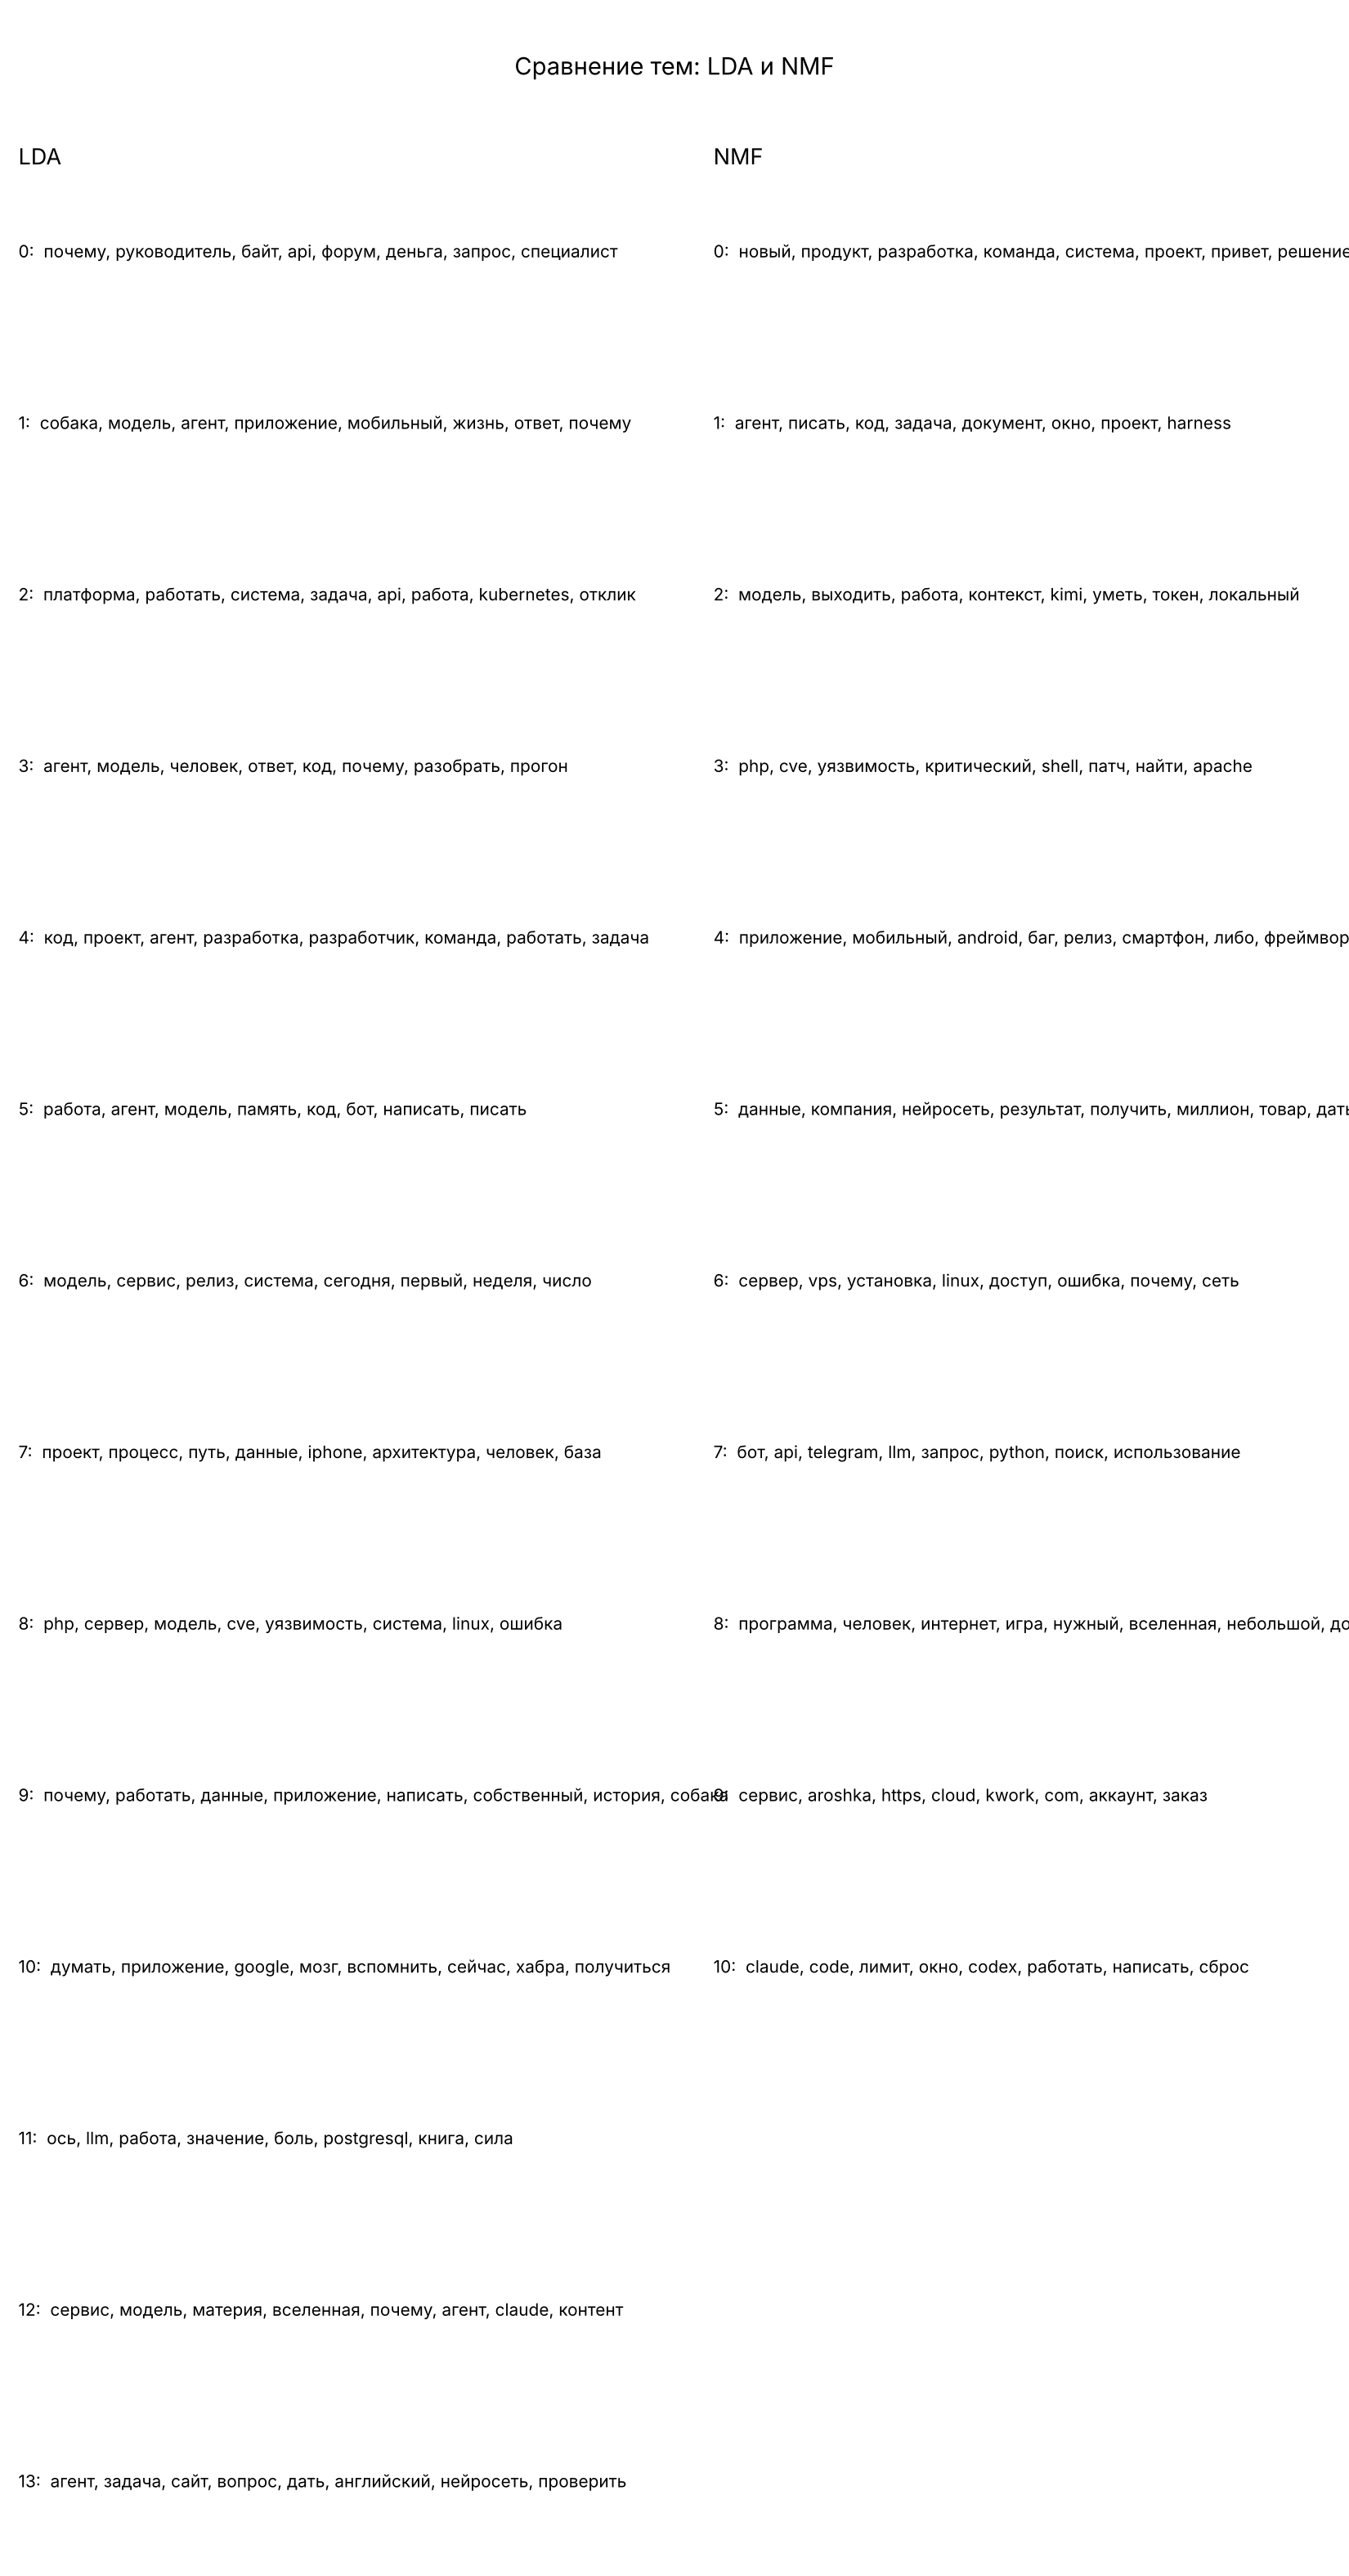

In [12]:
show("news_auto_compare.png", width=1100)

## Второй датасет: товары

In [13]:
run("topic_modeling.py", "--dataset", "products", "--method", "nmf",
    "--topics", "8", "--output", "product_categories", tail=10)

$ topic_modeling.py --dataset products --method nmf --topics 8 --output product_categories


Датасет: products
  документов: загружено 245, отброшено коротких 33, в работе 212
  словарь после фильтрации: 1231 слов
  NMF: тем 8, coherence c_v = 0.8000
Результаты: /tmp/claude-0/-home-claude/37419b0e-7b34-5281-aca7-ee316eaa2693/scratchpad/project/lab5/output
  product_categories_documents_nmf.csv
  product_categories_documents_nmf.png
  product_categories_topics.json
  product_categories_topwords_nmf.png
  product_categories_wordcloud_nmf.png


0

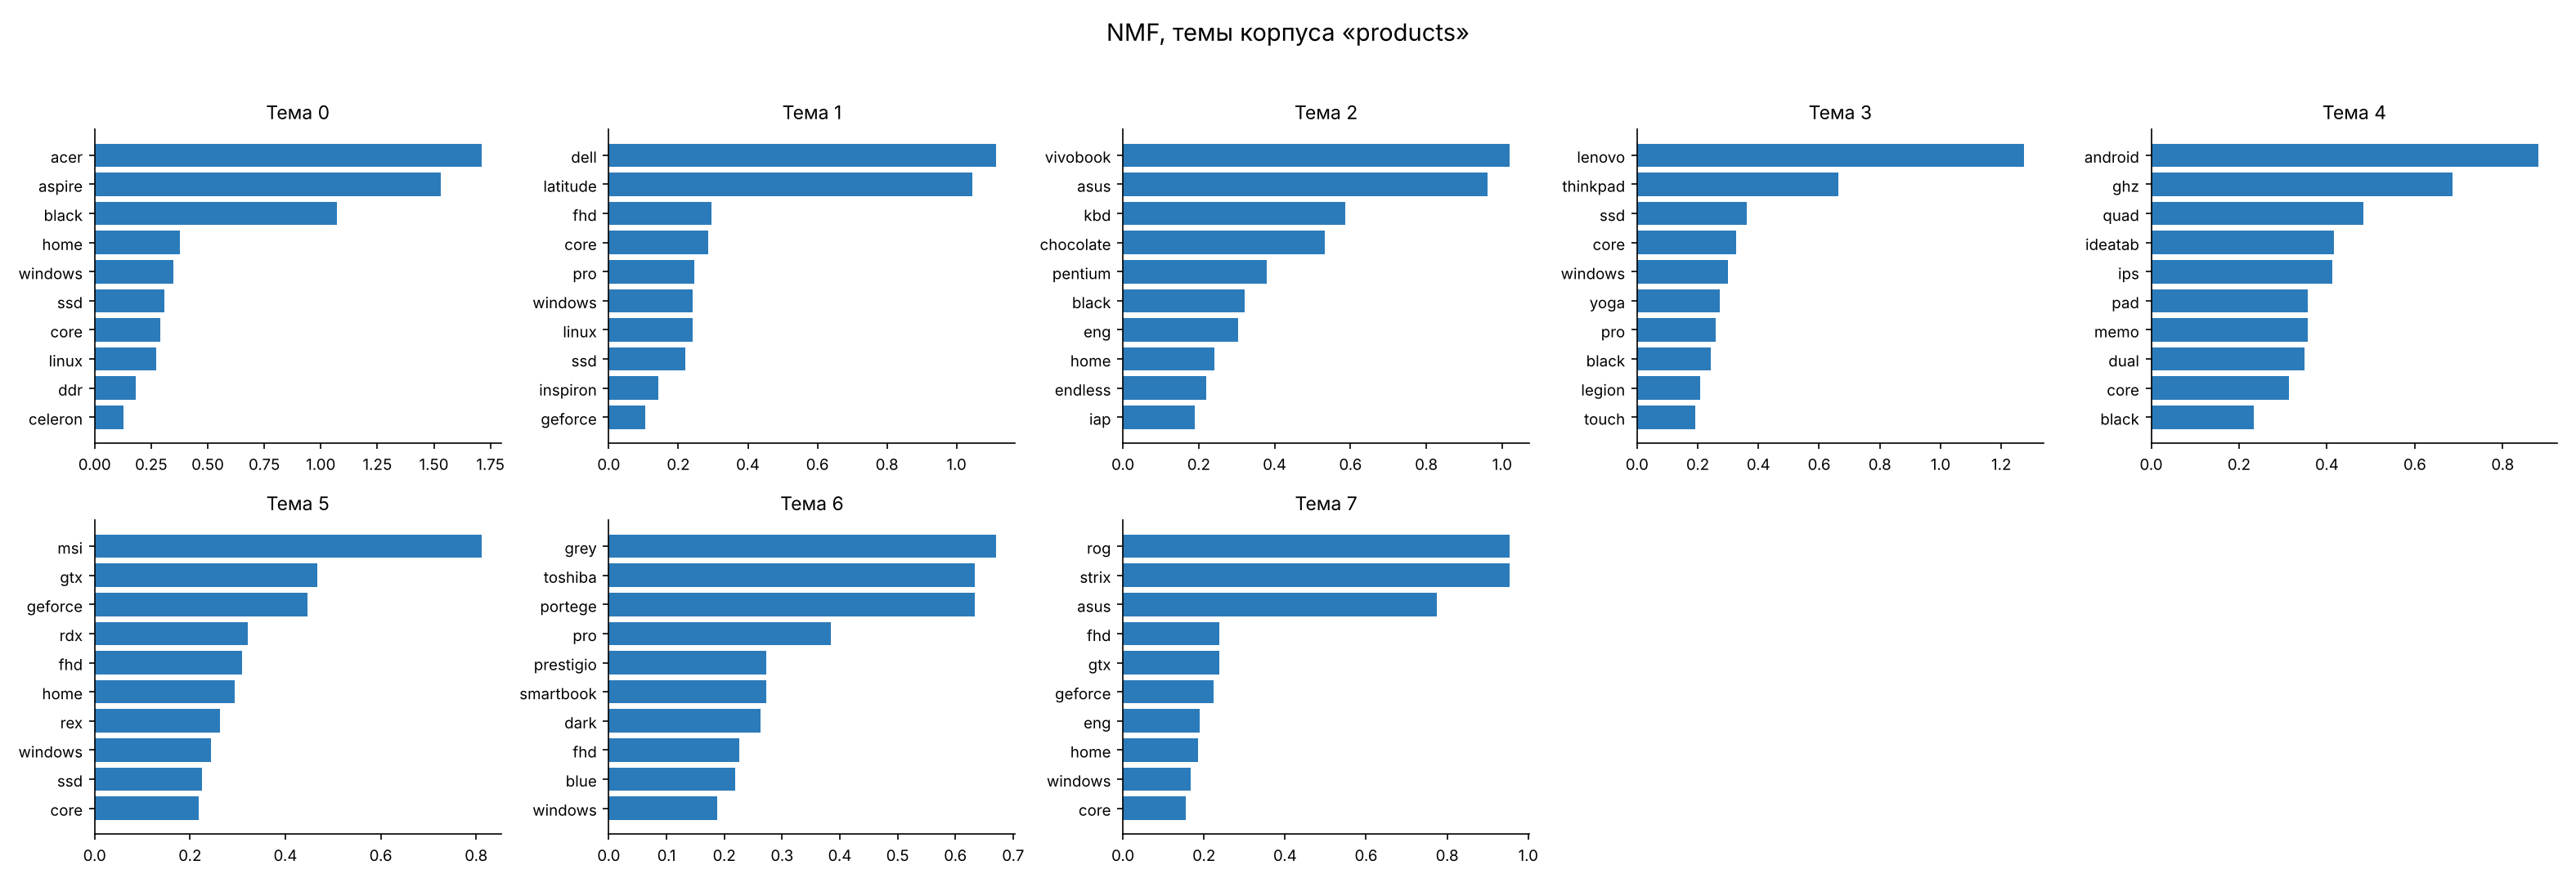

In [14]:
show("product_categories_topwords_nmf.png", width=1400)

---
# Задание 2: кластеризация городов по кухне

Города кодируются векторами частотности блюд: значение измерения — доля страниц
о кухне города, где это блюдо упомянуто. Дальше три метода кластеризации.

Сбор данных требует интернета. Если он есть, раскомментируйте первую строку —
она соберёт данные из Википедии в `data/city_dishes.json`. Без сбора используется
демонстрационный набор, и это будет видно в выводе.

In [15]:
# run("city_clustering.py", "--collect", tail=15)

data_file = LAB / "data" / "city_dishes.json"
if not data_file.exists():
    data_file = LAB / "data" / "demo_city_dishes.json"
print("используется:", data_file.name)

используется: demo_city_dishes.json


In [16]:
run("city_clustering.py", "--clusters", "4", "--output", "cities",
    "--data", data_file, tail=20)

$ city_clustering.py --clusters 4 --output cities --data /tmp/claude-0/-home-claude/37419b0e-7b34-5281-aca7-ee316eaa2693/scratchpad/project/lab5/data/demo_city_dishes.json


ВНИМАНИЕ: это демонстрационный набор, а не собранные данные.
Настоящие данные: python city_clustering.py --collect
Городов: 10, измерений (блюд): 47
  kmeans       : [0] Казань, Уфа | [1] Новосибирск, Хабаровск, Владивосток | [2] Пермь, Кунгур | [3] Петрозаводск, Москва, Санкт-Петербург
  hierarchical : [0] Новосибирск, Хабаровск, Владивосток | [1] Петрозаводск, Москва, Санкт-Петербург | [2] Казань, Уфа | [3] Пермь, Кунгур
  spectral     : [0] Петрозаводск, Москва, Санкт-Петербург | [1] Пермь, Кунгур | [2] Новосибирск, Хабаровск, Владивосток | [3] Казань, Уфа
  согласие hierarchical и kmeans: 1.00
  согласие hierarchical и spectral: 1.00
  согласие kmeans и spectral: 1.00
  методы согласны — разбиение устойчивое
  silhouette максимален при k = 6
  топ блюд кластера 0: чак-чак, эчпочмак, беляш, кыстыбый, бешбармак
  топ блюд кластера 1: строганина, красная икра, краб, папоротник, позы
  топ блюд кластера 2: пистики, посикунчики, шаньги, пиканы, кулебяка
  топ блюд кластера 3: шаурма, ух

0

Проекция городов на плоскость и проверка числа кластеров:

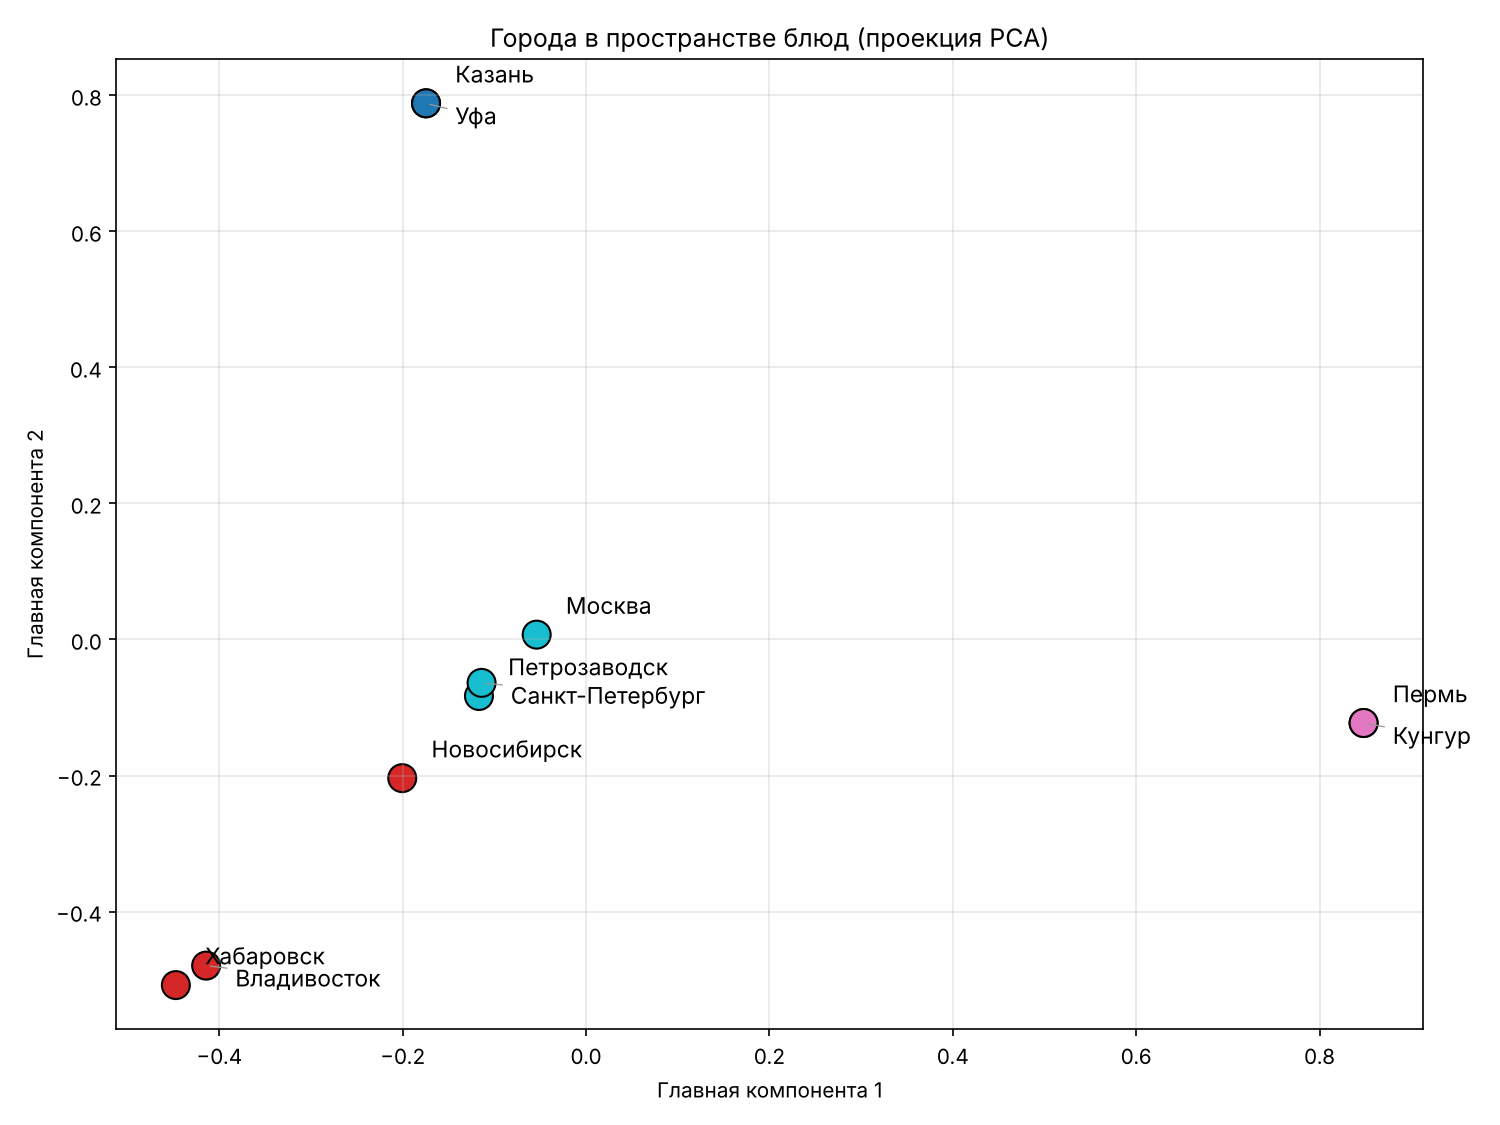

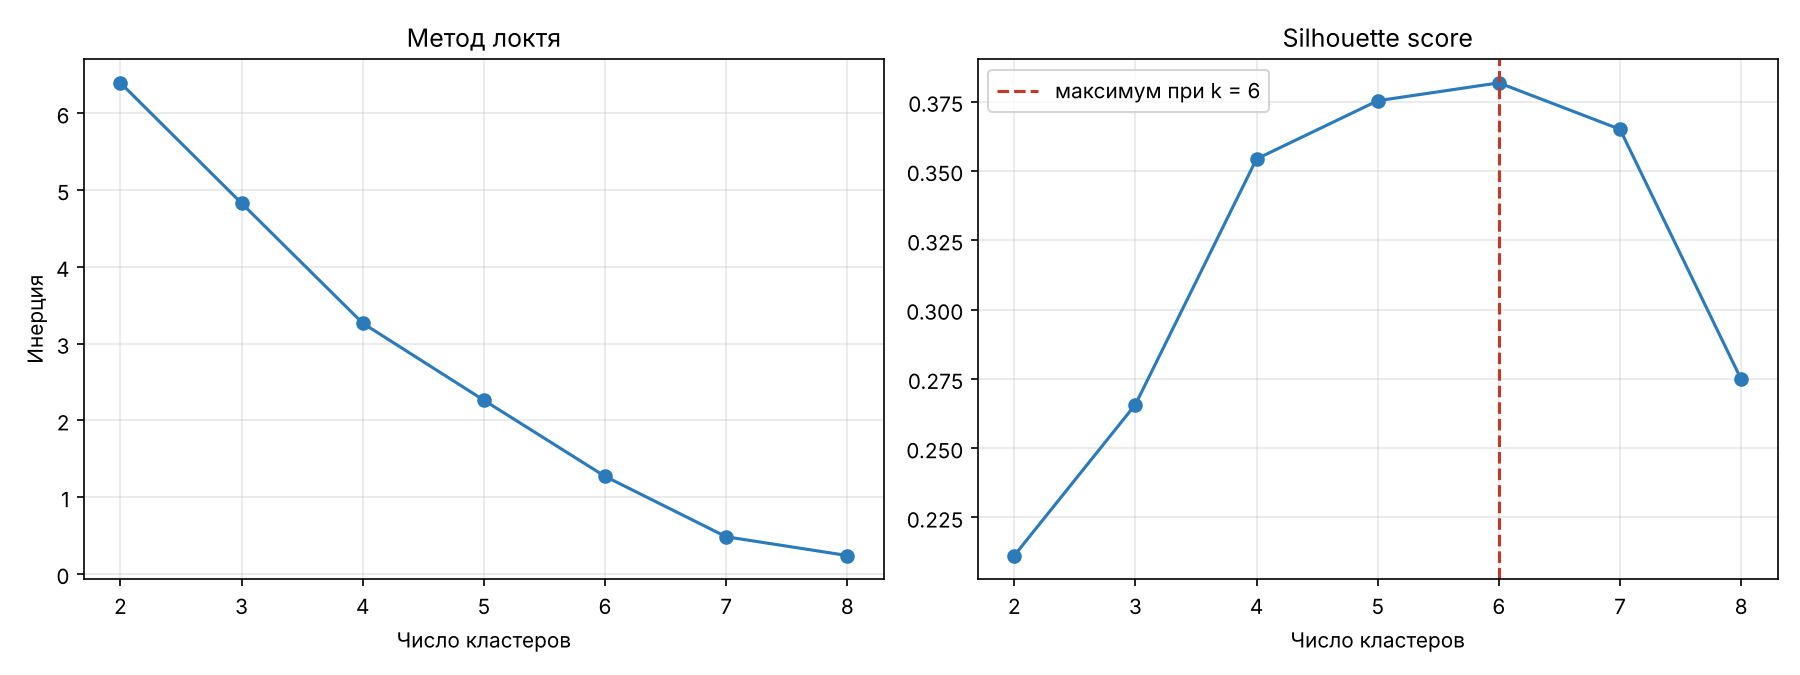

In [17]:
show("cities_clusters.png", width=1000)
show("cities_evaluation.png", width=1100)

In [18]:
report = json.loads((OUTPUT / "cities_clusters.json").read_text(encoding="utf-8"))

print("Согласие методов (индекс Rand, 1.0 — полное совпадение):")
for pair, score in report["agreement"].items():
    print(f"  {pair:28} {score:.2f}")
print()
print("Топ блюд по кластерам:")
for label, dishes in sorted(report["top_dishes"].items()):
    print(f"  кластер {label}: {', '.join(dishes)}")

Согласие методов (индекс Rand, 1.0 — полное совпадение):
  hierarchical и kmeans        1.00
  hierarchical и spectral      1.00
  kmeans и spectral            1.00

Топ блюд по кластерам:
  кластер 0: чак-чак, эчпочмак, беляш, кыстыбый, бешбармак
  кластер 1: строганина, красная икра, краб, папоротник, позы
  кластер 2: пистики, посикунчики, шаньги, пиканы, кулебяка
  кластер 3: шаурма, уха, корюшка, оливье, калитки


---
# Выводы

**NMF даёт более интерпретируемые темы, чем LDA.** На новостном корпусе из 240 документов
coherence у NMF 0.54 против 0.35 у LDA, и превосходство держится на всём диапазоне K.
В темах NMF видны осмысленные группы: документация и API, полнотекстовый поиск, агенты
и тестирование, нейросети. У LDA в тех же темах больше частотных слов общего характера.
Это совпадает с лекцией: на коротких текстах вероятностная модель хуже разделяет темы.
NMF ещё и быстрее — перебор всего диапазона K занимает секунды против десятков секунд.

**Максимум coherence не означает лучшее число тем.** Подбор дал K = 11 для NMF и K = 14
для LDA. При 240 документах это уже приемлемо, но на первом прогоне, когда новостей было
121, максимум уходил на K = 17 и K = 19 — по шесть-семь документов на тему, то есть
модель дробила корпус вместо поиска структуры. Вывод практический: метрика поощряет
дробление, и чем меньше корпус, тем сильнее. Смотреть надо на график: разумный K там,
где кривая выходит на полку, а темы ещё можно назвать словами.

**Высокая coherence не равна осмысленности.** Самый высокий показатель получился
на товарах — 0.80 против 0.54 у новостей. Но темы товаров это не темы, а семейства
моделей: Acer Aspire, Dell Latitude, Lenovo ThinkPad, Asus ROG Strix, планшеты
на Android. Названия моделей встречаются вместе почти идеально, поэтому формальная
согласованность слов максимальна, хотя содержательно модель просто сгруппировала
товары по брендам. Метрику нельзя читать в отрыве от самих топиков.

**Качество упирается в стоп-слова.** После первого прогона в топе тем сидели «это»,
«мочь», «самый», а в корпусе товаров — английские `more`, `one`, `all`, `who`, из-за
англоязычных описаний книг. Пополнение списка стоп-слов подняло coherence товаров
с 0.75 до 0.80 и убрало одну полностью мусорную тему из восьми. Это самый дешёвый
способ улучшить результат.

**Описания решают.** Пока паук практики 2 собирал только названия товаров, из 138 записей
в работу проходило 59, а темы строились по обрывкам названий. После доработки паука,
который заходит на карточку товара за описанием, в работе 212 документов из 245, медиана
длины выросла с 7 до 14 слов, и темы стали читаемыми. На одних названиях тематическое
моделирование не работает.

**Кластеризация городов устойчива.** Три метода — k-means, иерархическая и спектральная —
дали одно и то же разбиение, индекс Rand между всеми парами равен 1.0. Это главный
признак того, что структура в данных есть, а не придумана методом. Содержательная проверка
сходится: Казань и Уфа вместе (татарская и башкирская кухни близки), Пермь и Кунгур вместе
(уральская), Хабаровск и Владивосток вместе (дальневосточная рыба и морепродукты).
Топ-блюда кластеров читаются без расшифровки.

**Общие блюда приходится исключать.** Борщ, блины и пельмени упоминаются почти везде
с одинаковой частотой, не несут различающей информации и размывают кластеры. Они помечены
в словаре и отбрасываются при построении матрицы. L2-нормализация строк нужна по той же
причине: без неё город, про который нашлось больше страниц, оказывается «ближе» ко всем
сразу просто из-за масштаба, а не из-за кухни.